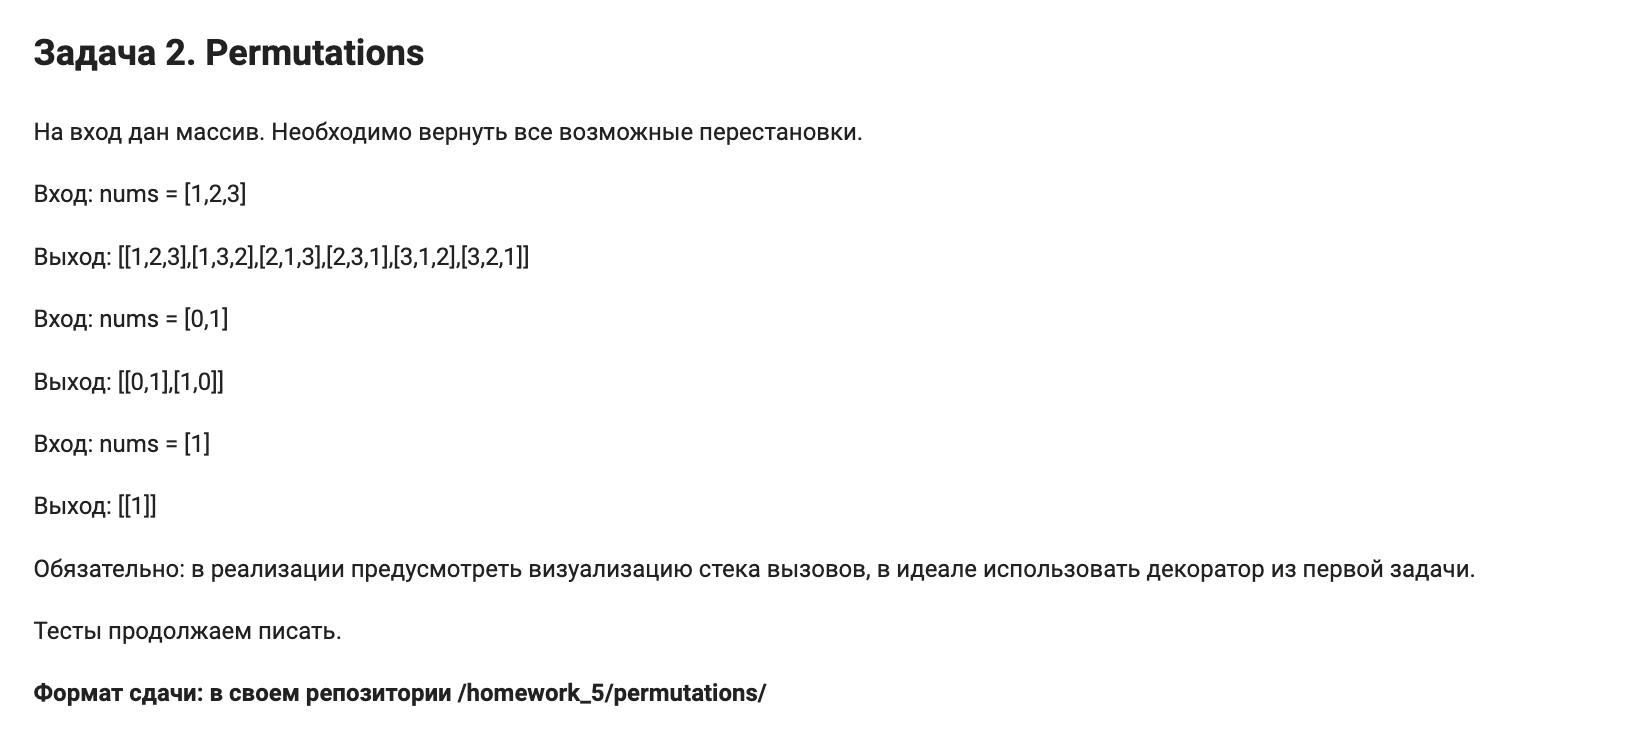

# Ход решения

Тут будем использовать  **backtracking** - рекурсивный перебор с возвратом, чтобы оптимально отсекать пути. Постепенно строим перестановку в списке `path`. Для каждого элемента массива с помощью `used` запоминаем, добавлен ли он в текущую перестановку.

В функции `backtrack` перебираем ещё не использованные элементы. Добавляем один элемент в `path`, вызываем рекурсию, а после возвращения удаляем его через `pop()` и снова отмечаем как неиспользованный. Так мы можем попробовать следующий вариант.

Когда длина `path` равна длине `nums`, перестановка готова. Сохраняем `path.copy()`, потому что дальше этот список будет меняться. Список `seen` не позволяет повторять одинаковое значение на одном уровне перебора, если во входном массиве есть дубликаты.

Для визуализации используем декоратор `tracer` из первой задачи. При `trace=True` он показывает вложенные вызовы `backtrack` с отступами. Без этого параметра функция просто возвращает ответ.

# Граничные случаи

- Если массив пустой, возвращаем `[[]]`: существует одна пустая перестановка.
- Если элемент один, возвращаем список с этой единственной перестановкой.
- Если в массиве есть повторяющиеся числа, возвращаем только уникальные перестановки.
- Исходный массив не изменяем.

# Сложность алгоритма

Пусть `n` — длина массива. В худшем случае все элементы различны, и перестановок будет `n!`.

- **Время:** `O(n · n!)`. Перебираем варианты и для каждой готовой перестановки копируем `n` элементов.
- **Память:** `O(n · n!)` для ответа. Без ответа — `O(n²)`: `path`, `used`, стек рекурсии и наборы `seen` на разных уровнях. При выключенном `trace` логи не создаются.

# Реализация алгоритма

Используем тот же простой `tracer`, что и в первой задаче. Приведём его здесь, чтобы ноутбук можно было запускать отдельно.

# Старая функция

In [1]:
from functools import wraps


def tracer(func):
    depth = 0

    @wraps(func)
    def wrapper(*args, **kwargs):
        nonlocal depth

        indent = "  " * depth
        print(f"{indent}{func.__name__}{args}")

        depth += 1
        try:
            result = func(*args, **kwargs)
        finally:
            depth -= 1

        print(f"{indent}{func.__name__} = {result}")
        return result

    return wrapper

# Новая функция с перестановками

In [2]:
def permutations(nums, trace=False):
    result = []
    used = [False] * len(nums)

    def backtrack(path):
        if len(path) == len(nums):
            result.append(path.copy())
            return

        seen = set()
        for i, value in enumerate(nums):
            if used[i] or value in seen:
                continue

            seen.add(value)
            used[i] = True
            path.append(value)
            backtrack(path)
            path.pop()
            used[i] = False

    if trace:
        backtrack = tracer(backtrack)

    backtrack([])
    return result

# Проверка на нетривиальном примере

In [3]:
nums = [1, 2, 3]
print(permutations(nums))

[[1, 2, 3], [1, 3, 2], [2, 1, 3], [2, 3, 1], [3, 1, 2], [3, 2, 1]]


# Визуализация работы алгоритма

Рассмотрим `nums = [1, 2, 3]`. Сначала выбираем `1`, затем `2`, затем `3`. Получив полный путь, сохраняем `[1, 2, 3]`. После этого возвращаемся назад, убираем `3` и `2` и пробуем другую ветку.

| Шаг | Действие | Текущий `path` |
| ---: | --- | --- |
| 1 | Начало | `[]` |
| 2 | Берём `1` | `[1]` |
| 3 | Берём `2` | `[1, 2]` |
| 4 | Берём `3`, сохраняем ответ | `[1, 2, 3]` |
| 5 | Убираем `3`, затем `2` | `[1]` |
| 6 | Берём `3`, затем `2`, сохраняем ответ | `[1, 3, 2]` |
| 7 | Убираем выбранные числа и возвращаемся к началу | `[]` |
| 8 | Начинаем с `2`, а затем с `3` | `[2, 1, 3]`, `[2, 3, 1]`, `[3, 1, 2]`, `[3, 2, 1]` |

Теперь включим `trace=True`. В выводе видны вызовы с разными значениями `path` и отступы по глубине рекурсии. Строка `backtrack = None` означает завершение вспомогательной функции: она складывает готовые перестановки в `result`, а сама ничего не возвращает.

In [4]:
result = permutations([1, 2, 3], trace=True)
print("Результат:", result)

backtrack([],)
  backtrack([1],)
    backtrack([1, 2],)
      backtrack([1, 2, 3],)
      backtrack = None
    backtrack = None
    backtrack([1, 3],)
      backtrack([1, 3, 2],)
      backtrack = None
    backtrack = None
  backtrack = None
  backtrack([2],)
    backtrack([2, 1],)
      backtrack([2, 1, 3],)
      backtrack = None
    backtrack = None
    backtrack([2, 3],)
      backtrack([2, 3, 1],)
      backtrack = None
    backtrack = None
  backtrack = None
  backtrack([3],)
    backtrack([3, 1],)
      backtrack([3, 1, 2],)
      backtrack = None
    backtrack = None
    backtrack([3, 2],)
      backtrack([3, 2, 1],)
      backtrack = None
    backtrack = None
  backtrack = None
backtrack = None
Результат: [[1, 2, 3], [1, 3, 2], [2, 1, 3], [2, 3, 1], [3, 1, 2], [3, 2, 1]]


# Тесты

Проверим три примера из условия, пустой массив, отрицательные числа, повторяющиеся элементы, сохранность входных данных и вывод `tracer`. Используем `unittest`, как в предыдущих задачах.

In [5]:
import unittest
from contextlib import redirect_stdout
from io import StringIO


class TestPermutations(unittest.TestCase):
    def test_examples(self):
        self.assertEqual(permutations([1, 2, 3]), [
            [1, 2, 3], [1, 3, 2],
            [2, 1, 3], [2, 3, 1],
            [3, 1, 2], [3, 2, 1],
        ])
        self.assertEqual(permutations([0, 1]), [[0, 1], [1, 0]])
        self.assertEqual(permutations([1]), [[1]])

    def test_empty(self):
        self.assertEqual(permutations([]), [[]])

    def test_negative_numbers(self):
        self.assertEqual(permutations([-1, 0]), [[-1, 0], [0, -1]])

    def test_duplicates(self):
        self.assertEqual(permutations([1, 1, 2]), [
            [1, 1, 2], [1, 2, 1], [2, 1, 1]
        ])

    def test_input_unchanged(self):
        nums = [3, 1, 2]
        self.assertEqual(len(permutations(nums)), 6)
        self.assertEqual(nums, [3, 1, 2])

    def test_trace(self):
        output = StringIO()
        with redirect_stdout(output):
            result = permutations([0, 1], trace=True)

        lines = output.getvalue().splitlines()
        self.assertEqual(result, [[0, 1], [1, 0]])
        self.assertEqual(lines[0], 'backtrack([],)')
        self.assertIn('  backtrack([0],)', lines)
        self.assertIn('    backtrack([0, 1],)', lines)
        self.assertEqual(lines[-1], 'backtrack = None')

    def test_without_trace(self):
        output = StringIO()
        with redirect_stdout(output):
            permutations([1, 2])
        self.assertEqual(output.getvalue(), '')


_ = unittest.main(argv=[''], exit=False)

.......
----------------------------------------------------------------------
Ran 7 tests in 0.009s

OK
